# TP2 : DEMPSTER-CHAFER #

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score,classification_report
from pyds import MassFunction, powerset
import functools

* **Chargement Du DataSet**

In [5]:
iris = load_iris()
df = pd.DataFrame(iris.data,
columns=iris.feature_names)
df["class"] = pd.Categorical.from_codes(iris.target,iris.target_names)
feature_cols = list(iris.feature_names)
varieties = list(df["class"].unique())
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


* **Distribution des Attributs:**

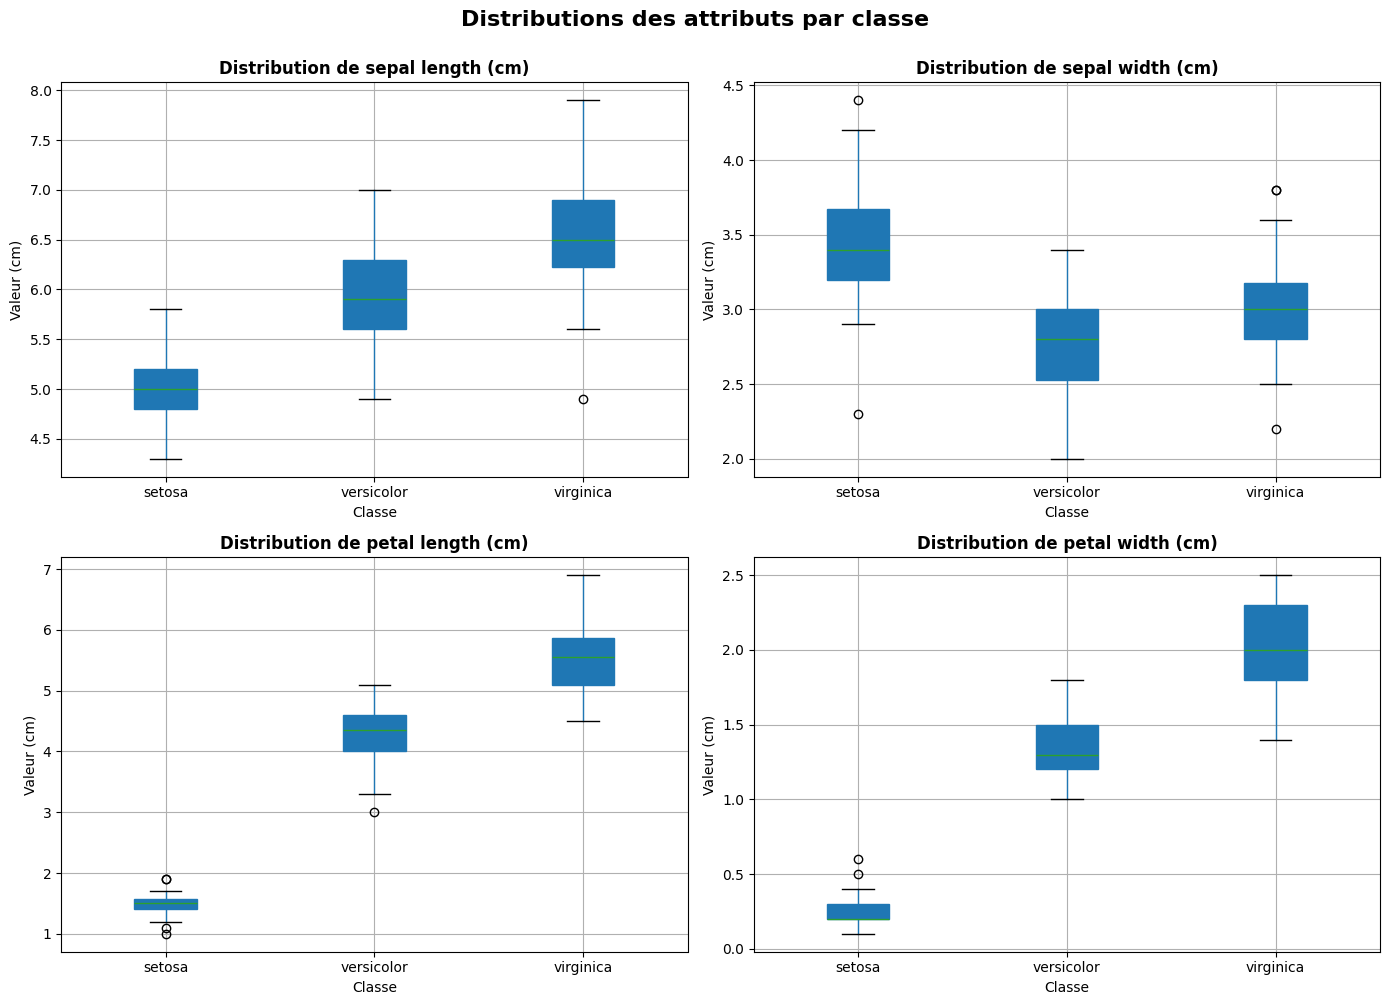

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
for idx, col in enumerate(feature_cols):
    ax = axes[idx]
    # Création du boxplot
    df.boxplot(column=col, by='class', ax=ax,patch_artist=True)
    # Personnalisation
    ax.set_title(f'Distribution de {col}',
    fontsize=12, fontweight='bold')
    ax.set_xlabel('Classe', fontsize=10)
    ax.set_ylabel('Valeur (cm)', fontsize=10)
ax.get_figure().suptitle('') # Retirer le titre automatique
plt.suptitle('Distributions des attributs par classe', fontsize=16,fontweight='bold', y=1.00)
plt.tight_layout()

* **Relation entre Attributs:**

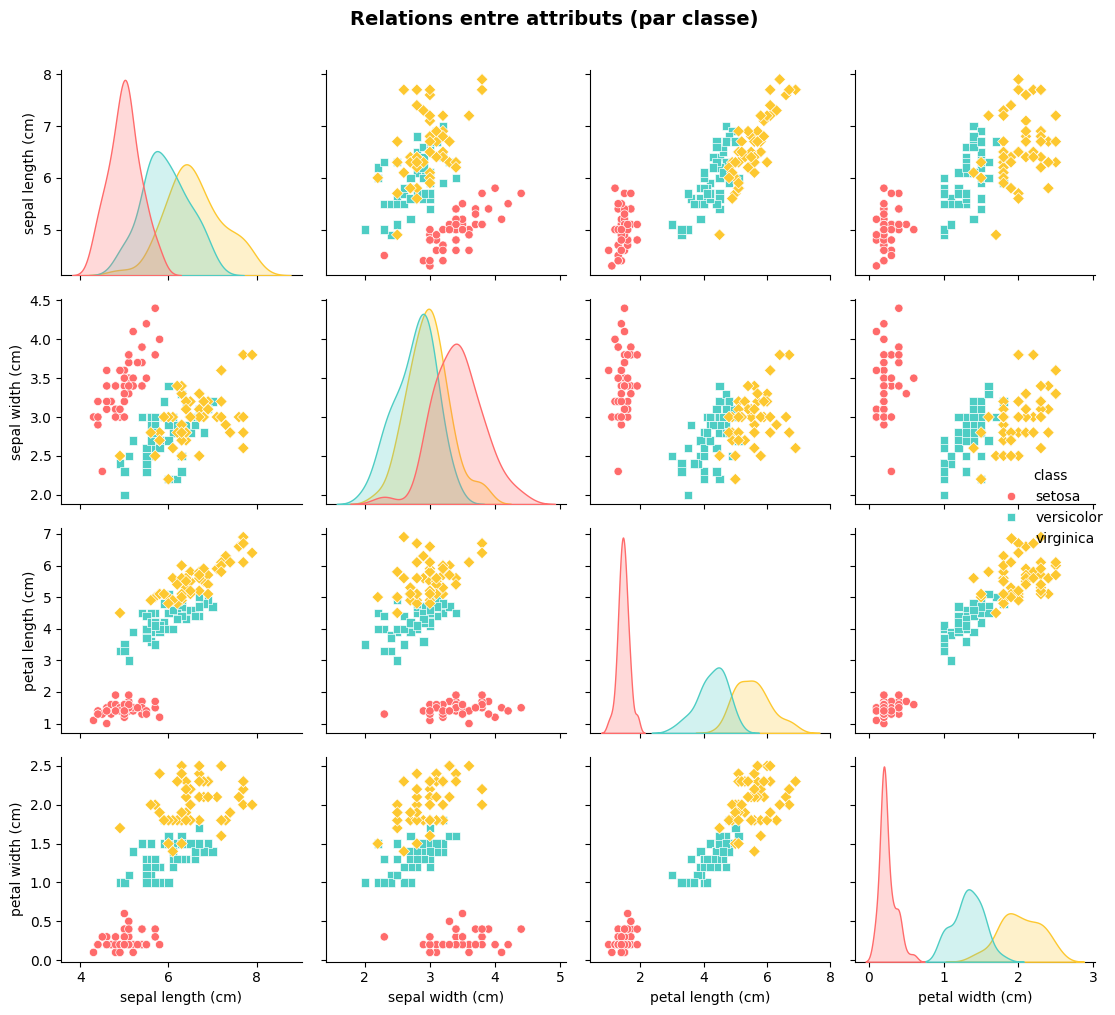

In [11]:
sns.pairplot(df, hue='class',palette=['#FF6B6B', '#4ECDC4','#FDC830'],diag_kind='kde', markers=['o', 's', 'D'])
plt.suptitle('Relations entre attributs (par classe)', y=1.01, fontsize=14,fontweight='bold')
plt.tight_layout()

* **Tache 01:**

$\quad \Rightarrow$ Le couple descriminant est: *Petal Length*, *Petal Width*

$\quad \Rightarrow$ On observe que la classe *Setosa* est presque totalement séparée des deux autres.

$\qquad $*Versicolor* et *Virginica* présentent un chevauchement,on le remarque dans certaines valeurs de longueur et largeur de pétales.

$\quad \Rightarrow$ On a utilisé la théorie de (D-S) car elle permet de représenter  *la certitude* , *l'incertitude* , *l'ignorance*.

$\qquad$ Pour prendre une décision , On utilise une *masse* qui n'est pas une probabilité classque. 

In [13]:
train_df, test_df = train_test_split(df,test_size=0.20, random_state=42,stratify=df["class"])

* **Tache 02:**

$\quad \Rightarrow$ *random-state = 42* permet de controler le hasard pendant la séparation des données , pour avoir le meme mélange à chaque éxecution.

$\quad \Rightarrow$ *stratify =df['classe]* sert à conserver les memes propotions des classes pour obtenir une séparation stable. 
